# NumPy: arreglos y operaciones vectorizadas

Representaremos rondas de temperatura de tres salas. Primero aprenderemos a leer
la forma de un arreglo;
 <br>después aplicaremos operaciones a todas las mediciones y
reutilizaremos los resultados en una aplicación.

## Contenido

1. Listas y arreglos; dimensiones y tipos.
2. Selección y máscaras.
3. Vistas y copias.
4. Operaciones vectorizadas, resúmenes por eje y broadcasting.
5. Mediciones incompletas y paso a una aplicación.

Abre esta notebook en VS Code desde `01-exploracion` y selecciona el kernel de `.venv`.
Los ejercicios tienen celdas independientes: puedes recorrer los ejemplos sin
completarlos y resolver cada ejercicio en su propia celda.


In [2]:
import sys
from pathlib import Path

import numpy as np

print(f"Python: {sys.executable}")
print(f"Working directory: {Path.cwd()}")
print(f"NumPy: {np.__version__}")

data_dir = Path.cwd().parent / "datos"
if not (data_dir / "readings.csv").is_file():
    raise FileNotFoundError(
        "Start the notebook from the 01-exploracion project directory"
    )

Python: E:\1 CLASES MAESTRIA\Maestria en IA\1er semestre\Apuntes\github\Programacion para IA\remoto_tarea\notebooks\Unidad 2\sesion-01-numpy\01-exploracion\.venv\Scripts\python.exe
Working directory: E:\1 CLASES MAESTRIA\Maestria en IA\1er semestre\Apuntes\github\Programacion para IA\remoto_tarea\notebooks\Unidad 2\sesion-01-numpy\01-exploracion
NumPy: 2.5.4


## 1. Listas y arreglos: ¿Por qué no usar listas de Python?

Las listas de Python son estructuras flexibles que pueden contener objetos de tipos distintos, pero esta versatilidad tiene un costo:
- cada elemento es un objeto completo en la memoria con su propia sobrecarga (*overhead*) de tipo y conteo de referencias.
- Además, los datos no están contiguos en la memoria RAM, lo que impide aprovechar las optimizaciones del procesador (como la vectorización por hardware y el uso de caché).

NumPy introduce el `ndarray` (n-dimensional array), un bloque de memoria contiguo y homogéneo (todos los elementos son del mismo tipo). Esto permite:
1. **Operaciones vectorizadas:** Aplicar cálculos a millones de elementos de golpe sin escribir ciclos `for` explícitos en Python.
2. **Eficiencia espacial y temporal:** Se reduce drásticamente el uso de memoria y se acelera el procesamiento gracias al código compilado en C subyacente.

Predice qué devuelve cada multiplicación en el siguiente bloque: una opera sobre una lista (duplicando su estructura) y la otra sobre los valores numéricos del arreglo.

La mayoría de los arrays de NumPy tienen ciertas restricciones.
Por ejemplo:

- Todos los elementos del array deben ser del mismo tipo de datos.
- Una vez creado, el tamaño total del array no puede cambiar.
- La forma debe ser «rectangular», no «irregular» (o *jagged*);

por ejemplo, cada fila de un array bidimensional debe tener el mismo número de columnas.

[Introducción oficial a NumPy](https://numpy.org/doc/stable/user/absolute_beginners.html).

In [3]:
temperature_list = [22.0, 24.0, 20.0]
temperature_array = np.array(temperature_list)

print(f"lista de temperaturas : {temperature_list * 2}")
print(f"lista de temperaturas * 2 :{temperature_array * 2}")

lista de temperaturas : [22.0, 24.0, 20.0, 22.0, 24.0, 20.0]
lista de temperaturas * 2 :[44. 48. 40.]


## 2. Dimensiones, forma y tamaño

Usaremos este orden de columnas: sala norte, sala sur y almacén. Cada fila
corresponde a una ronda en la que se midieron las tres salas.

| Ronda | `north_room` | `south_room` | `storage_room` |
|-------|-------------:|-------------:|---------------:|
| 0     |           22 |           24 |             20 |
| 1     |           23 |           25 |             21 |
| 2     |           24 |           26 |             22 |

- `loadtxt` lee valores numéricos;
- `skiprows=1` omite el encabezado
- y `ndmin=2` mantiene al menos dos dimensiones,

Incluso para un archivo de una sola fila.

- [**"El orden de los nombres se conserva por acuerdo con el archivo, no dentro del arreglo."**]

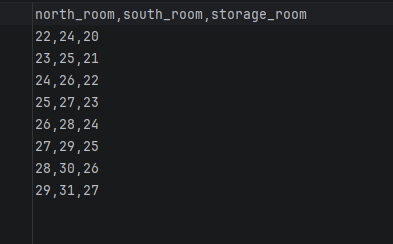

La [ficha de datos](../datos/README.md) describe las unidades y su origen.

[Referencia de loadtxt](https://numpy.org/doc/stable/reference/generated/numpy.loadtxt.html).

In [4]:
room_names = ("north_room", "south_room", "storage_room")
readings = np.loadtxt(data_dir / "readings.csv", delimiter=",", skiprows=1, ndmin=2) # al dejar ndmin=2 se garantiza que si se tiene 100 filas o solo 1 siempre se reciba una tabla 2D (filas, columnas)
print(readings)

[[22. 24. 20.]
 [23. 25. 21.]
 [24. 26. 22.]
 [25. 27. 23.]
 [26. 28. 24.]
 [27. 29. 25.]
 [28. 30. 26.]
 [29. 31. 27.]]


Comprender la anatomía de un `ndarray` es crucial para evitar errores de dimensionalidad en machine learning y procesamiento de datos:

- **`ndim` (Número de ejes):** Representa la cantidad de dimensiones.
    - Un vector tiene 1 eje (filas o elementos),
    - una matriz tiene 2 ejes (filas y columnas),
    - y los tensores de aprendizaje profundo suelen tener 3 o más.
- **`shape` (Forma):** Una tupla que indica cuántos elementos hay en cada eje `(filas, columnas)`. Es la propiedad más consultada al depurar operaciones de álgebra lineal o redes neuronales.
- **`size` (Tamaño total):** El producto total de las dimensiones (`shape`), es decir, el número absoluto de elementos almacenados.
- **`nbytes` vs `itemsize`:** `itemsize` indica cuántos bytes ocupa un solo elemento según su tipo de dato (por ejemplo, 8 bytes para un `float64`). `nbytes` mide el tamaño total del búfer de datos en la memoria RAM, lo cual es vital para dimensionar conjuntos de datos masivos.

```text
                         axis 1: salas →
                      norte   sur   almacén
axis 0: rondas ↓   0   22     24      20
                   1   23     25      21
                   2   24     26      22
                   …

```

Parametros completos de un ndarray para inicializar:

* **dtype** tipo de datos, opcional Cualquier objeto que pueda interpretarse como un tipo de datos de numpy. Por defecto es numpy.float64.
* **buffer** objeto que expone la interfaz de buffer, opcional Usado para rellenar el arreglo con datos.
* **offset** entero, opcional Desplazamiento de los datos del arreglo en el buffer.
* **strides** tupla de enteros, opcional Desplazamientos de los datos en la memoria.
* **order** {‘C’, ‘F’}, opcional Orden por filas (estilo C) o por columnas (estilo Fortran).







[Propiedades de ndarray](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.html).

In [5]:
import numpy as np
c_style = np.ndarray(shape=(2,2), dtype=np.float64, order='C')
print(f"{c_style}\n")

fortran_style=np.ndarray(shape=(2,2), dtype=np.float64, order='F')
print(f"{fortran_style}\n")


# order='C'
# order='F'
# El parámetro No cambia cómo se imprime la matriz en pantalla, sino cómo se guarda en la memoria RAM de tu computadora.

[[0.00000000e+000 1.39348377e-311]
 [1.39348377e-311 1.39348377e-311]]

[[0.00000000e+000 1.39348377e-311]
 [1.39348377e-311 1.39348377e-311]]



In [6]:
print(f"Dimensions: {readings.ndim}")
print(f"Shape: {readings.shape}")
print(f"Elements: {readings.size}")
print(f"Data type: {readings.dtype}")
print(f"Bytes per element: {readings.itemsize}")
print(f"Data bytes: {readings.nbytes}")
assert readings.size == 8 * 3

Dimensions: 2
Shape: (8, 3)
Elements: 24
Data type: float64
Bytes per element: 8
Data bytes: 192


In [7]:
scalar = np.array(22.0)
vector = np.array([22.0, 24.0, 20.0])
matrix = np.array([[22.0, 24.0, 20.0]])
for name, values in [("scalar", scalar), ("vector", vector), ("matrix", matrix)]:
    print(name, values.ndim, values.shape, values.size)

scalar 0 () 1
vector 1 (3,) 3
matrix 2 (1, 3) 3


---

## Buenas practicas
Al usar np.ndarray(shape=...) estás creando una matriz vacía sin inicializar.
Lo que ves en pantalla no es cero, sino cualquier residuo que haya quedado en la memoria RAM en ese instante.

Si quieres inicializar matrices con ceros o unos controlando el orden, es más seguro usar:

In [8]:
c_style = np.zeros((2, 2), order='C')
fortran_style = np.zeros((2, 2), order='F')

---

1. [x] terminado

### <span style="color:red">Ejercicio 1: una ronda, dos representaciones</span>

Construye `one_round` como vector de tres temperaturas y `one_round_table`
como matriz de una fila. Comprueba las formas `(3,)` y `(1, 3)`. Explica por qué
ambos tienen tres elementos y distinto número de ejes.

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [9]:
# Write your solution here.
one_round = np.array([25.0,32.0,38.0])
one_round_table= np.array([[25.0,32.0,38.0]])
assert one_round.shape == (3,) ,f"shape is not correct"
assert one_round_table.shape == (1, 3),f"shape is  not correct"

print(f"vector {one_round}\n")
print(f"matrix {one_round_table}\n")


vector [25. 32. 38.]

matrix [[25. 32. 38.]]



## 3. Tipos numéricos y coerción de tipos (`dtype`)
(enfatizar el casting y los riesgos de mezclar tipos)

- El tipo de dato (`dtype`) de un arreglo determina el espacio que ocupa en memoria y el rango de valores permitidos. A diferencia de las listas, un `ndarray` **no puede tener tipos mixtos**.

- Si intentas introducir un valor decimal en un arreglo declarado como entero (`int64`), NumPy realizará un truncamiento implícito en lugar de lanzar un error inmediato. Si mezclas números con cadenas de texto (como `"missing"`), todo el arreglo sufrirá un proceso de **coerción**, transformándose por completo en un arreglo de strings (`<U...`), lo que inutilizará el arreglo para cualquier operación matemática posterior.

- `np.testing.assert_allclose(actual, expected)`: Es la herramienta estándar para comparar arreglos flotantes permitiendo una pequeña tolerancia ante errores
 numéricos de punto flotante.
- `assert_array_equal`: Exige una coincidencia absoluta, tanto en forma como en valores exactos.

[Tipos de datos de NumPy](https://numpy.org/doc/stable/user/basics.types.html).

In [10]:
integer_readings = np.array([22, 24, 20], dtype=np.int64)
integer_readings[0] = 22.75
print(integer_readings)

float_readings = np.array([22, 24, 20], dtype=np.float64)
float_readings[0] = 22.75
print(float_readings)
print(np.array([22, "missing"]).dtype)
np.testing.assert_allclose(float_readings[0], 22.75)
np.testing.assert_array_equal(integer_readings, [22, 24, 20])

[22 24 20]
[22.75 24.   20.  ]
<U21


2. [x] terminado

### <span style="color:red">Ejercicio 2: preservar una temperatura decimal</span>


Crea un arreglo con `22`, `24` y `20` que permita sustituir el primer valor por
`22.75` sin truncarlo. Comprueba el valor con `np.testing.assert_allclose`.

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [11]:
# Write your solution here.
# Solución para el Ejercicio 2
exercise_2 = np.array([22, 24, 20], dtype=np.float64)
exercise_2[0] = 22.75

# Comprobación
np.testing.assert_allclose(exercise_2[0], 22.75)
print("Arreglo flotante:", exercise_2)

Arreglo flotante: [22.75 24.   20.  ]


## 4. Selección de filas, columnas y rebanado (*Slicing*)

La indexación en arreglos multidimensionales utiliza la sintaxis `readings[fila, columna]`.

Una regla fundamental que debes dominar es la diferencia entre usar un **índice entero** y un **slice (`:`)**:
- Un **índice entero** (ej. `readings[0]`) extrae una fila específica y **elimina esa dimensión** del resultado, reduciendo el rango del arreglo (`ndim` disminuye en 1).
- Un **slice** (ej. `readings[0:1]` o `readings[:, 0:1]`) extrae la misma información pero **conserva la dimensión original**, lo cual es indispensable para mantener la compatibilidad en operaciones de *broadcasting* posterior.

[Selección de elementos y slicing](https://numpy.org/doc/stable/user/basics.indexing.html).

In [12]:
print(readings[0,1])
print(readings[-1])
print(readings[:3,:2])
print(readings[:,0])
print(readings[:,0:1])
print(readings[:, 0].shape, readings[:, 0:1].shape)

24.0
[29. 31. 27.]
[[22. 24.]
 [23. 25.]
 [24. 26.]]
[22. 23. 24. 25. 26. 27. 28. 29.]
[[22.]
 [23.]
 [24.]
 [25.]
 [26.]
 [27.]
 [28.]
 [29.]]
(8,) (8, 1)


Una lista de índices permite escoger columnas no consecutivas. Comprueba el
orden resultante: `[2, 0]` coloca primero el almacén y después la sala norte.

In [13]:
selected_rooms = readings[:, [2, 0]]
print(selected_rooms[:2])
print(selected_rooms.shape)

[[20. 22.]
 [21. 23.]]
(8, 2)


3. [x] terminado

### <span style="color:red">Ejercicio 3: últimas rondas</span>


Obtén las últimas tres rondas para sala norte y almacén, en ese orden. El
resultado debe ser `[[27, 25], [28, 26], [29, 27]]`, de forma `(3, 2)`.
Comprueba valores y forma.

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [14]:
# Write your solution here.
import sys
from pathlib import Path

import numpy as np

data_dir = Path.cwd().parent / "datos"
if not (data_dir / "readings.csv").is_file():
    raise FileNotFoundError(
        "Start the notebook from the 01-exploracion project directory"
    )

readings = np.loadtxt(
    data_dir / "readings.csv",
    delimiter=",",
    skiprows=1,
    ndmin=2,
    dtype=int
)


last_reading_1 =  readings[5:8,[0,2]]
last_reading_2 = readings[-3:, [0, 2]] #conteo invertido

print(f"shape reading_1: {last_reading_1.shape}\n")

print(f"Shape rading_2: {last_reading_2.shape}\n")
print(f"matriz reading_2: {last_reading_2}")

assert last_reading_1.shape == (3,2), "the shape is not correct"
assert last_reading_2.shape == (3,2), "the shape is not correct"

np.testing.assert_array_equal(last_reading_1, [[27, 25], [28, 26], [29, 27]], "the data is not correct")
np.testing.assert_array_equal(last_reading_2, [[27, 25], [28, 26], [29, 27]], "the data is not correct")

shape reading_1: (3, 2)

Shape rading_2: (3, 2)

matriz reading_2: [[27 25]
 [28 26]
 [29 27]]


EJEMPLO DE SLICING EN MATRICES TODOS LOS CASOS:

In [15]:
case1 = readings[:,:]
print(case1)

[[22 24 20]
 [23 25 21]
 [24 26 22]
 [25 27 23]
 [26 28 24]
 [27 29 25]
 [28 30 26]
 [29 31 27]]


In [16]:
case1 = readings[:1,:]
print(case1)

[[22 24 20]]


In [17]:
case1 = readings[1:,:]
print(case1)

[[23 25 21]
 [24 26 22]
 [25 27 23]
 [26 28 24]
 [27 29 25]
 [28 30 26]
 [29 31 27]]


In [18]:
case1 = readings[:,1:2]
print(case1)

[[24]
 [25]
 [26]
 [27]
 [28]
 [29]
 [30]
 [31]]


In [19]:
case1 = readings[:1,:1]
print(case1)

[[22]]


In [20]:
case1 = readings[:1,1:]
print(case1)

[[24 20]]


4. [x] terminado

### <span style="color:red">Ejercicio 4: una columna con dos ejes</span>

Selecciona la sala sur conservando la forma `(8, 1)`. Contrasta la expresión
con una selección que devuelva `(8,)`. Explica qué eje desapareció.

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [21]:
# Write your solution here.
#El de forma (8,):Es un arreglo unidimensional (1D). Es una colección plana de
# 8 elementos donde solo existe un eje (ndim = 1).
# El de forma (8, 1): Es estrictamente un vector columna (2D) bidimensional (ndim = 2),
# porque tiene 8 filas y 1 sola columna.

south_room = readings[:,1]
print(f"South room \n{south_room}\n")
print(f"shape : \n{south_room.shape}")

contrast_selection = readings[:, 1:2]
print(f"contrast selection: \n{contrast_selection}\n")
print(f"shape : \n{contrast_selection.shape}")




South room 
[24 25 26 27 28 29 30 31]

shape : 
(8,)
contrast selection: 
[[24]
 [25]
 [26]
 [27]
 [28]
 [29]
 [30]
 [31]]

shape : 
(8, 1)


## 5. Máscaras booleanas

Una comparación produce un booleano por elemento. Para seleccionar rondas usando
una sala, la máscara debe tener una posición por fila. `&` combina condiciones
por elemento; cada comparación necesita paréntesis.

- Una máscara booleana es un arreglo de valores `True` o `False` de la misma longitud o forma que el arreglo original.
- Al aplicar una máscara unidimensional sobre el eje 0 (filas), NumPy filtra filas completas.

- Sin embargo, si aplicas una máscara booleana a toda la matriz (con la misma forma de `(8, 3)`), NumPy aplana el resultado y devuelve un **vector unidimensional**
con todos los elementos individuales que cumplieron la condición, perdiendo la estructura de filas y columnas original.

- Ten esto en cuenta dependiendo de si necesitas analizar rondas completas o valores aislados.


In [22]:
north_temperatures = readings[:, 0]
warm_rounds = north_temperatures >= 27
print(warm_rounds)
print()

trues = len(warm_rounds[warm_rounds == True])
print(trues)
print()
print(warm_rounds.shape)
print(readings[warm_rounds])

print()
comfortable_rounds = (north_temperatures >= 24) & (north_temperatures < 27)
print(readings[comfortable_rounds])

[False False False False False  True  True  True]

3

(8,)
[[27 29 25]
 [28 30 26]
 [29 31 27]]

[[24 26 22]
 [25 27 23]
 [26 28 24]]


Una máscara del mismo tamaño que toda la matriz selecciona celdas y devuelve
un vector. Ya no conserva una fila por ronda. Compara ambas selecciones antes de
usar el resultado en un resumen.

In [23]:
cell_mask = readings >= 28
print(cell_mask.shape)
print(readings[cell_mask])
print(readings[cell_mask].shape)
print(readings[readings[:, 1] >= 28].shape)

(8, 3)
[28 29 28 30 29 31]
(6,)
(4, 3)


5. [x] terminado

### <span style="color:red"> Ejercicio 5: un intervalo</span>

Selecciona las rondas cuya temperatura de la sala sur esté entre `26` incluido
y `29` excluido. Deben quedar tres filas completas. Escribe la máscara, imprime
su forma y comprueba las temperaturas `[26, 27, 28]` de esa columna.

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [24]:
# Write your solution here.
print(f"north_room, south_room, storage_room")
print(f"---------------------------------")
np.set_printoptions(formatter={'int_kind': lambda x: f"{x:6d}"})
print(f"{readings}")

print(f"---------------------------------")

south_room = readings[:,1]
print(f"south room only: \n{south_room}")
mask= (south_room>=26)&(south_room<29)
print(f"Masked shape: \n {mask.shape}")

masked_reading = south_room[mask]
print(f"masked readings : \n{masked_reading}")

np.testing.assert_array_equal(masked_reading, [26,27,28], "the masked data is not correct")


north_room, south_room, storage_room
---------------------------------
[[    22     24     20]
 [    23     25     21]
 [    24     26     22]
 [    25     27     23]
 [    26     28     24]
 [    27     29     25]
 [    28     30     26]
 [    29     31     27]]
---------------------------------
south room only: 
[    24     25     26     27     28     29     30     31]
Masked shape: 
 (8,)
masked readings : 
[    26     27     28]


## 6. Vistas y copias: El talón de Aquiles del rendimiento

Para evitar duplicar datos masivamente en la memoria RAM y agilizar los cálculos, la mayoría de las operaciones de selección en NumPy (como los *slices* básicos)
no copian los datos, sino que generan una **vista (*view*)** que apunta exactamente al mismo búfer de memoria subyacente.

- **Modificar una vista modifica el arreglo original.** Si esto ocurre sin intención, puede corromper tus fuentes de datos de entrada.
- Para garantizar el aislamiento de los datos, debes invocar explícitamente el método `.copy()`.
- Las selecciones mediante listas de índices enteros o máscaras booleanas **siempre generan copias**, nunca vistas.

[Copias y vistas](https://numpy.org/doc/stable/user/basics.copies.html).

In [25]:
working_readings = readings.copy()
north_view = working_readings[:, 0]
north_copy = working_readings[:, 0].copy()
print(np.shares_memory(working_readings, north_view))
print(np.shares_memory(working_readings, north_copy))
north_view[0] = -10
print(working_readings[0, 0], north_copy[0], readings[0, 0])

True
False
-10 22 22


In [26]:
warm_copy = readings[readings[:, 0] >= 27]
warm_copy[0, 0] = -20
print(np.shares_memory(readings, warm_copy))
print(readings[5, 0])

edited_readings = readings.copy()
edited_readings[edited_readings[:, 0] >= 27, 0] = 27
print(edited_readings[:, 0])

False
27
[    22     23     24     25     26     27     27     27]


Obtener una selección con máscara crea una copia, pero asignar directamente
con `array[mask] = value` modifica el arreglo destino. La distinción está en qué
objeto recibe la asignación.

6. [x] terminado

### <span style="color:red">Ejercicio 6: una selección independiente</span>

Crea `last_rounds` con las dos últimas rondas, cambia su primera temperatura
a `100` y comprueba que `readings` sigue igual que antes. Usa `copy()` y
`np.testing.assert_array_equal` para demostrarlo.

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [27]:
# Write your solution here.
last_rounds = readings[-2:].copy()
print(f"ultimos rounds copia: \n{last_rounds}\n")

valor_original = readings[-2:].copy()
print(f"valor original: \n{valor_original}\n")

last_rounds[0,0]=100
print(f"ultimos rounds modificado: \n{last_rounds}\n")


np.testing.assert_array_equal(
    readings[-2:],
    valor_original,
    err_msg="El arreglo original readings fue modificado (la copia no funcionó)"
)

ultimos rounds copia: 
[[    28     30     26]
 [    29     31     27]]

valor original: 
[[    28     30     26]
 [    29     31     27]]

ultimos rounds modificado: 
[[   100     30     26]
 [    29     31     27]]



## 7. Operaciones vectorizadas y resúmenes por eje

En una operación vectorizada expresamos qué cálculo aplicar al arreglo completo.
La conversión de Celsius a Fahrenheit conserva las ocho rondas y las tres salas.
El ciclo siguiente produce el mismo resultado y sirve para comparar las dos formas
de expresar el cálculo; no hace falta medir velocidad con solo 24 valores.

[Operaciones con arreglos](https://numpy.org/doc/stable/user/quickstart.html).


In [28]:
fahrenheit = readings * 9 / 5 + 32
fahrenheit_with_loop = np.array(
    [[temperature * 9 / 5 + 32 for temperature in row] for row in readings]
)
np.testing.assert_allclose(fahrenheit, fahrenheit_with_loop)
print(fahrenheit[:2])
print(fahrenheit.shape)

[[71.6 75.2 68. ]
 [73.4 77.  69.8]]
(8, 3)


7. [x] terminado

### <span style="color:red">Ejercicio 7: convertir y conservar la forma</span>


Crea `converted_readings` con todas las temperaturas en Fahrenheit mediante una
operación sobre el arreglo, sin escribir un ciclo. Comprueba la forma `(8, 3)`,
que la primera fila sea `[71.6, 75.2, 68.0]` y que `readings` no cambió.


In [29]:
# Write your solution here.
before= readings.copy()

converted_readings= readings*9/5+32

assert converted_readings.shape == (8,3)
print(converted_readings)

[[71.6 75.2 68. ]
 [73.4 77.  69.8]
 [75.2 78.8 71.6]
 [77.  80.6 73.4]
 [78.8 82.4 75.2]
 [80.6 84.2 77. ]
 [82.4 86.  78.8]
 [84.2 87.8 80.6]]


### Resumir por eje

Una reducción elimina el eje sobre el que opera. `axis=0` combina las rondas y
conserva las tres salas; `axis=1` combina las salas y conserva las ocho rondas.
Aquí todas las columnas tienen la misma unidad, así que una media por ronda tiene
sentido. Más adelante no promediaremos sin más columnas como edad y tarifa.

[Promedios con `numpy.mean`](https://numpy.org/doc/stable/reference/generated/numpy.mean.html).


In [30]:
room_means = readings.mean(axis=0)
round_means = readings.mean(axis=1)
print(room_means, room_means.shape)
print(round_means[:3], round_means.shape)
np.testing.assert_allclose(room_means, [25.5, 27.5, 23.5])

[25.5 27.5 23.5] (3,)
[22. 23. 24.] (8,)


In [31]:
print(readings.sum())

print(readings.mean())

612
25.5


### Broadcasting: una media distinta para cada sala

- El *broadcasting* (o transmisión) es el mecanismo estrella de NumPy que permite realizar operaciones aritméticas entre arreglos que tienen diferentes tamaños (*shapes*). En lugar de marcar un error o forzarte a duplicar datos manualmente, NumPy "estira" o copia virtualmente el arreglo más pequeño a lo largo de las dimensiones necesarias para que coincida con el más grande.

- ¡Y lo hace sin gastar memoria extra!

---

Para que dos arreglos sean compatibles para el *broadcasting*, NumPy compara sus formas **alineándolas desde la derecha hacia la izquierda**. Dos dimensiones son compatibles si:
1. Son exactamente iguales, o
2. Una de ellas tiene un valor de `1`.

---

- El broadcasting (o transmisión) es el mecanismo que usa NumPy para realizar operaciones aritméticas
entre arreglos que tienen diferentes tamaños (shapes).
En lugar de marcar un error o forzarte a duplicar datos manualmente, NumPy "estira" o copia virtualmente
el arreglo más pequeño a lo largo de las dimensiones necesarias para que coincida con el más grande.

- ¡Y lo hace sin gastar memoria extra!

---

`readings` tiene forma `(8, 3)` y `room_means` forma `(3,)`. NumPy alinea las
tres posiciones con las tres columnas y resta cada media a las ocho rondas.

`room_means.reshape(1, 3)` muestra explícitamente esa fila de tres valores;
produce el mismo resultado. NumPy compara las dimensiones desde la derecha: en cada posición deben ser
iguales o una de ellas debe valer 1. Una forma `(8,)` no se alinearía con las
tres columnas. El ejemplo captura ese error para poder continuar.

[Reglas de broadcasting](https://numpy.org/doc/stable/user/basics.broadcasting.html).


In [32]:
deviations = readings - room_means
explicit_row = room_means.reshape(1, 3)
print(readings.shape, room_means.shape, explicit_row.shape)
print(deviations[:2])
assert deviations.shape == readings.shape
np.testing.assert_allclose(deviations, readings - explicit_row)
np.testing.assert_allclose(deviations.mean(axis=0), [0, 0, 0], atol=1e-12)

try:
    readings - round_means
except ValueError as error:
    print("Incompatible shapes:", readings.shape, round_means.shape)
    print(error)

(8, 3) (3,) (1, 3)
[[-3.5 -3.5 -3.5]
 [-2.5 -2.5 -2.5]]
Incompatible shapes: (8, 3) (8,)
operands could not be broadcast together with shapes (8,3) (8,) 


## 8. Mediciones incompletas y control de calidad de datos

En escenarios reales de adquisición de datos, es común encontrarnos con valores faltantes, corrompidos o erróneos que se representan como `NaN` (*Not a Number*) o infinitos (`inf`). Operar directamente con estos valores puede propagar errores o invalidar los análisis estadísticos posteriores.

Para abordar esto de forma robusta, NumPy ofrece herramientas especializadas:
- **`np.isfinite(array)`**: Evalúa elemento por elemento y devuelve una máscara booleana indicando cuáles valores son números reales válidos (excluyendo tanto `NaN` como `+inf` y `-inf`).
- **`all(axis=1)`**: Permite aplicar una política estricta a nivel de filas. Al evaluar una matriz bidimensional, exige que **todos** los elementos de una misma ronda (en este caso, todas las salas) sean finitos para conservar la fila completa. Si tan solo una celda presenta un valor inválido, toda la ronda se descarta.

Esta regla de limpieza es un compromiso: por un lado, garantiza la consistencia dimensional y evita sesgos al comparar salas; por el otro, implica la pérdida de información válida de las salas que sí midieron correctamente en esa ronda. Por ello, cuantificar el número de filas aceptadas y rechazadas es un paso obligatorio en cualquier tubería (*pipeline*) de preprocesamiento.


`isfinite` identifica valores distintos de `nan` y los infinitos. `all(axis=1)`
exige que las tres posiciones de una ronda sean finitas. Usaremos esa política
para conservar las mismas rondas en todas las salas.

Es una regla del ejercicio: eliminar una fila también descarta mediciones válidas
de sus otras salas. La decisión debe quedar visible en el conteo de rechazos.

[isfinite](https://numpy.org/doc/stable/reference/generated/numpy.isfinite.html) ·
[all](https://numpy.org/doc/stable/reference/generated/numpy.all.html).

In [33]:
quality_readings = np.loadtxt(
    data_dir / "readings_quality.csv", delimiter=",", skiprows=1, ndmin=2
)
finite_cells = np.isfinite(quality_readings)
complete_rows = finite_cells.all(axis=1) # revision por fila  ------  axis = 0 revision por columna

print(f"quality readings: \n {quality_readings}\n")

print(f"True/false Matrix isfinite cells: \n {finite_cells}\n") # https://numpy.org/doc/stable/reference/generated/numpy.isfinite.html
print(f"complete rows: \n{complete_rows}\n")
print(f"Quality readings: \n{quality_readings[complete_rows]}")

quality readings: 
 [[22. 24. 20.]
 [23. nan 21.]
 [24. 26. 22.]
 [25. 27. inf]]

True/false Matrix isfinite cells: 
 [[ True  True  True]
 [ True False  True]
 [ True  True  True]
 [ True  True False]]

complete rows: 
[ True False  True False]

Quality readings: 
[[22. 24. 20.]
 [24. 26. 22.]]


8. [x] terminado

### <span style="color:red">Ejercicio 8: contar los rechazos</span>

Cuenta las filas aceptadas y rechazadas de `quality_readings`. Comprueba que
son dos y dos, y que las medias del arreglo seleccionado son `[23, 25, 21]`.
¿Qué pasaría si no quedara ninguna fila completa?

Anticipa el resultado antes de ejecutar. Anota después qué comprobaste.

In [34]:
# Write your solution here.
accepted_count = complete_rows.sum()
rejected_count = (~complete_rows).sum()

print(f"Filas aceptadas: {accepted_count}")
print(f"Filas rechazadas: {rejected_count}")

assert accepted_count == 2, "El número de filas aceptadas debe ser 2"
assert rejected_count == 2, "El número de filas rechazadas debe ser 2"

selected_readings = quality_readings[complete_rows]
means = selected_readings.mean(axis=0)
print(f"Medias de las salas seleccionadas: {means}")

np.testing.assert_allclose(means, [23, 25, 21])

Filas aceptadas: 2
Filas rechazadas: 2
Medias de las salas seleccionadas: [23. 25. 21.]


9. [x] terminado

### <span style="color:red">Ejercicio 9: diferencias respecto de la media</span>

Calcula la media de cada sala y réstala de readings sin un ciclo por ronda.
- Comprueba la forma (8, 3)
- y que la media de cada columna de diferencias sea aproximadamente cero.
- Explica cómo se alinean las formas (8, 3) y (3,)
- y por qué no se resta la media general.

In [42]:
# Ejercicio 9
#(ignore)
np.set_printoptions(formatter={
    'int_kind': lambda x: f"{x:6d}",
    'float_kind': lambda x: f"{x:6.1f}"  # 6 espacios en total, 1 decimal
})


print(f"readings shape:\n{readings.shape}\n")
print(f"readings:\n{readings}\n")

room_means = readings.mean(axis=0)  # Forma: (3,)
print(f"media:\n {room_means}\n")

deviations = readings - room_means  # Forma: (8, 3) *ver nota debajo
print(f"Desviacion:\n {deviations}\n")

assert deviations.shape == (8, 3), f"La forma esperada es (8, 3), pero se obtuvo {deviations.shape}"


np.testing.assert_allclose(deviations.mean(axis=0), [0.0, 0.0, 0.0], atol=1e-12)

print("Forma de las diferencias:", deviations.shape)
print("Media de cada columna de diferencias:", deviations.mean(axis=0))

readings shape:
(8, 3)

readings:
[[    22     24     20]
 [    23     25     21]
 [    24     26     22]
 [    25     27     23]
 [    26     28     24]
 [    27     29     25]
 [    28     30     26]
 [    29     31     27]]

media:
 [  25.5   27.5   23.5]

Desviacion:
 [[  -3.5   -3.5   -3.5]
 [  -2.5   -2.5   -2.5]
 [  -1.5   -1.5   -1.5]
 [  -0.5   -0.5   -0.5]
 [   0.5    0.5    0.5]
 [   1.5    1.5    1.5]
 [   2.5    2.5    2.5]
 [   3.5    3.5    3.5]]

Forma de las diferencias: (8, 3)
Media de cada columna de diferencias: [   0.0    0.0    0.0]


Explicacion:

Broadcasting(permitir realizar operacions entre arrays de numpy, que son de diferente tamaño):
primero se alinean las formas que se tienen (8,3) con (3, )
- La dimensión más a la derecha de readings es 3 (columnas / salas).
- La dimensión de room_means es 3.

NumPy automáticamente "extiende" o proyecta ese vector de 3 elementos hacia abajo en las 8 filas.
De este modo,
le restara la primera columna la media de la sala norte, a la segunda la de la sala sur
y a la tercera la del almacén.
sin escribir un ciclo for


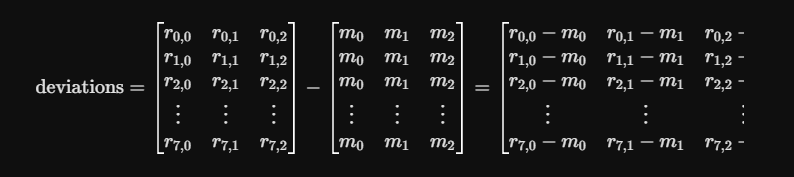


cada sala representa un tipo y sus mediciones las variaciones, hacer una media TOTAL por los 24 registros mezcla tipos por lo que no es adecuado y es mejor operar con un vector de 3 que represente dichos tipos luego usando un poco lo que se sabe de numpy y el tema de broadcasting que nos permitira estirar este vector para cumplir con los requerimientos de la aritmetica de vectores... habremos desbloqueado la habilidad completa respetando TODO el ciclo de la informacion que se esta generando.




## Continuación: llevar las operaciones al proyecto

En el proyecto `02-reporte-mediciones`, estas operaciones forman funciones que
se importan desde una notebook y desde `main.py`. Sigue la [guía](../GUIA.md) para
cambiar de proyecto y abrir `u2_n2_reporte_mediciones.ipynb`.

Antes de continuar, reinicia el kernel y ejecuta todas las celdas. Los resultados
no deben depender de haber ejecutado una celda fuera de orden.

Referencias a revisar:

https://www.youtube.com/watch?v=xECXZ3tyONo